# From paddle error to spikes
The court has unit height, with positive $y$ pointing down. The sensory signal is $g=y_{\rm ball}-y_{\rm paddle}$. Nine groups prefer gaps $\mu_k$ from $-0.8$ to $+0.8$. The sensory current delivered to the eight excitatory cells in group $k$ is

$$I_k(g)=14\exp\!\left[-\frac{(g-\mu_k)^2}{2(0.12)^2}\right].$$

Each group also has two inhibitory cells. All 90 cells receive background and recurrent current. The readout pools excitatory spikes within each group with a 40 ms exponential filter.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from model import AssemblyConfig, SpikingAssemblies

config = AssemblyConfig()
network = SpikingAssemblies(config, seed=101)
time = np.arange(360)
gap = np.where(time < 180, -0.4, 0.4)
spikes, features = [], []
for value in gap:
    spikes.append(network.step(value))
    features.append(network.features()[:-1])
features = np.asarray(features)
print(f'{network.weights.shape[0]} cells; {np.count_nonzero(network.weights)} fixed recurrent connections')

90 cells; 838 fixed recurrent connections


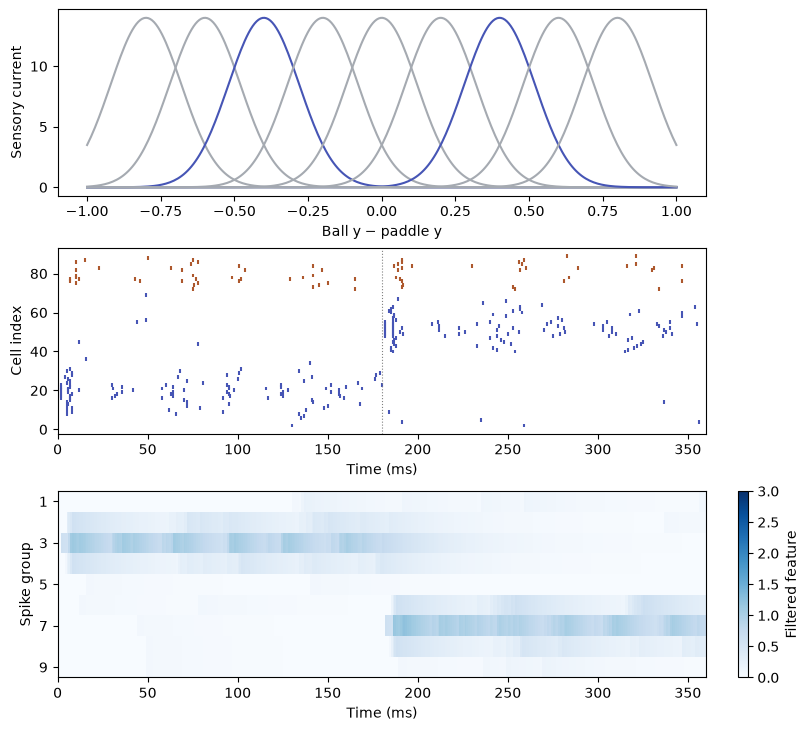

In [2]:
fig, (tuning, raster, heat) = plt.subplots(3, 1, figsize=(8, 7.2), layout='constrained')
g = np.linspace(-1, 1, 300)
for center in network.centers:
    response = config.input_current * np.exp(-0.5 * ((g - center) / config.tuning_width)**2)
    color = '#4655b5' if np.isclose(abs(center), 0.4) else '#a5aab1'
    tuning.plot(g, response, color=color)
tuning.set(xlabel='Ball y − paddle y', ylabel='Sensory current')
milliseconds, cell_ids = np.nonzero(spikes)
raster.scatter(milliseconds, cell_ids, s=8, marker='|',
               c=np.where(cell_ids < config.n_excitatory, '#4655b5', '#ad582d'))
raster.axvline(180, color='gray', linestyle=':', linewidth=0.8)
raster.set(xlim=(0, 360), xlabel='Time (ms)', ylabel='Cell index')
image = heat.imshow(features.T, extent=(0, 360, 9.5, 0.5), aspect='auto',
                    cmap='Blues', vmin=0, vmax=3, interpolation='nearest')
heat.set(xlabel='Time (ms)', ylabel='Spike group', yticks=[1, 3, 5, 7, 9])
fig.colorbar(image, ax=heat, label='Filtered feature')
plt.show()

At 180 ms the ball switches from above the paddle to below it. The active group shifts, and the filtered rates carry a brief memory of the earlier input. Try a gap of zero to see which groups represent an aligned paddle.